# 02 · Exploratory Data Analysis (EDA)

**WIE3007 Data Mining — Group Project** · Section owner: **jx**

This notebook explores the simulated loan dataset before feature engineering and modelling.
It checks data quality, looks at how each column is distributed, and finds which columns are
related to the target `loan_default`.

- **Input:** `data/financial_loan_dataset_v2.csv`
- **Output:** figures and tables saved to `results/` with the prefix `eda_`

## 1. Setup and data loading

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, PercentFormatter
from scipy import stats

DATA_PATH = Path("../data/financial_loan_dataset_v2.csv")
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)

TARGET = "loan_default"
NUMERIC_COLS = ["age", "annual_income", "credit_score", "loan_amount",
                "debt_to_income_ratio", "late_payments_12m", "account_tenure_months"]
LABELS = {
    "age": "Age (years)",
    "annual_income": "Annual income",
    "credit_score": "Credit score",
    "loan_amount": "Loan amount",
    "debt_to_income_ratio": "Debt-to-income ratio",
    "late_payments_12m": "Late payments (last 12 months)",
    "account_tenure_months": "Account tenure (months)",
    "employment_status": "Employment status",
    "loan_default": "Loan default",
}

# Chart style: blue = repaid / general, orange = defaulted
BLUE, ORANGE, RED, GREY, SURFACE = "#2a78d6", "#eb6834", "#e34948", "#52514e", "#fcfcfb"
sns.set_theme(style="whitegrid", rc={
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "grid.color": "#e1e0d9", "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
thousands = FuncFormatter(lambda x, _: f"{x / 1000:,.0f}K")

df = pd.read_csv(DATA_PATH)
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
df.head()

Rows: 1,200 | Columns: 11


,customer_id,age,annual_income,credit_score,loan_amount,debt_to_income_ratio,late_payments_12m,account_tenure_months,employment_status,loan_default,customer_remark
0,CUST_10000,41,80043.63,676,45583.93,0.226,1,97,Full-Time,0,Budgetary position appears resilient with clea...
1,CUST_10001,27,43477.54,552,12642.27,0.124,3,46,Self-Employed,1,Meeting was routine and focused on verifying p...
2,CUST_10002,46,53191.19,533,41992.38,0.255,5,104,Full-Time,1,Applicant is seeking capital to expand a small...
3,CUST_10003,48,51973.73,675,14470.02,0.231,1,77,Contract,0,Follow-up contact is scheduled for early next ...
4,CUST_10004,24,91622.57,699,41091.96,0.272,1,14,Full-Time,0,Client submitted additional reference details ...


| Column | Description |
|---|---|
| `customer_id` | Unique customer identifier (not a predictor) |
| `age` | Customer age in years |
| `annual_income` | Yearly income |
| `credit_score` | Credit score, 300–850 (higher is better) |
| `loan_amount` | Loan amount requested |
| `debt_to_income_ratio` | Existing debt relative to income (0–1) |
| `late_payments_12m` | Number of late payments in the last 12 months |
| `account_tenure_months` | Months the customer has held an account |
| `employment_status` | Full-Time, Self-Employed, Part-Time or Contract |
| `customer_remark` | Loan officer's free-text note |
| `loan_default` | **Target** — 1 = defaulted, 0 = repaid |

## 2. Data quality

In [2]:
print(f"Duplicated rows       : {df.duplicated().sum()}")
print(f"Duplicated customer_id: {df['customer_id'].duplicated().sum()}")
pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "unique": df.nunique()})

Duplicated rows       : 0
Duplicated customer_id: 0


,dtype,missing,unique
customer_id,str,0,1200
age,int64,0,46
annual_income,float64,0,1200
credit_score,int64,0,328
loan_amount,float64,0,1200
debt_to_income_ratio,float64,0,368
late_payments_12m,int64,0,9
account_tenure_months,int64,0,118
employment_status,str,0,4
loan_default,int64,0,2


**Findings**
- No missing values and no duplicates, so no cleaning or imputation is needed.
- `customer_id` is unique per row and must be dropped before modelling.

## 3. Target and employment status

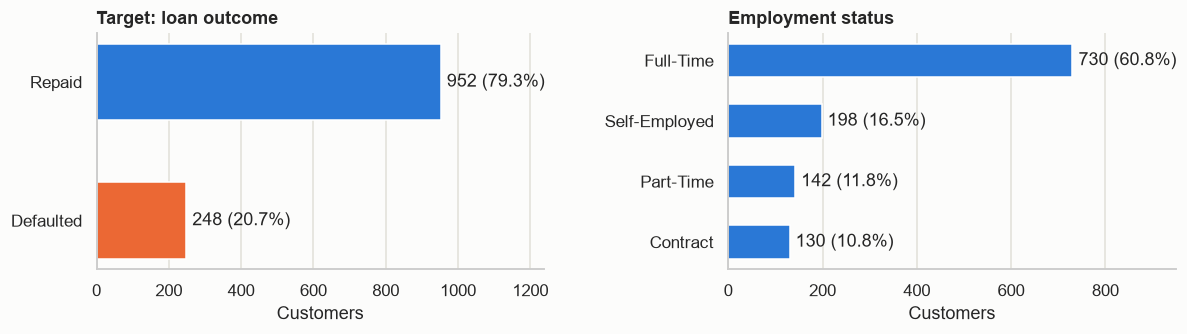

In [3]:
overall_rate = df[TARGET].mean()
target_counts = df[TARGET].map({0: "Repaid", 1: "Defaulted"}).value_counts()
employment_counts = df["employment_status"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, counts, colors, title in [
    (axes[0], target_counts, [BLUE, ORANGE], "Target: loan outcome"),
    (axes[1], employment_counts, BLUE, "Employment status"),
]:
    bars = ax.barh(counts.index, counts.values, color=colors, height=0.55)
    ax.bar_label(bars, labels=[f"{v:,} ({v / len(df):.1%})" for v in counts.values], padding=4)
    ax.invert_yaxis()
    ax.set_xlim(0, counts.max() * 1.3)
    ax.set_title(title)
    ax.set_xlabel("Customers")
    ax.grid(axis="y", visible=False)

fig.tight_layout(w_pad=3)
fig.savefig(RESULTS_DIR / "eda_01_target_and_employment.png")
plt.show()

**Findings**
- **20.7% of customers defaulted** (248) and 79.3% repaid (952), so the classes are imbalanced.
- Predicting "repaid" for everyone already gives 79.3% accuracy. Models should therefore be judged on F1-score and ROC-AUC, using a stratified train/test split.
- Most customers (60.8%) are full-time employees.

## 4. Numeric feature distributions

In [4]:
summary = df[NUMERIC_COLS].describe().T
summary["skew"] = df[NUMERIC_COLS].skew()
summary.to_csv(RESULTS_DIR / "eda_summary_statistics.csv")
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
age,1200.0,38.91,9.20,21.00,32.00,39.00,45.00,69.00,0.31
annual_income,1200.0,65718.15,32558.61,18584.82,42824.46,58417.75,81438.26,249396.16,1.42
credit_score,1200.0,654.78,75.54,383.00,605.00,656.00,705.00,843.00,-0.13
loan_amount,1200.0,30362.81,22821.75,5080.37,14223.62,23041.10,39327.18,147106.00,1.77
debt_to_income_ratio,1200.0,0.25,0.10,0.06,0.18,0.24,0.30,0.72,0.95
late_payments_12m,1200.0,1.25,1.31,0.00,0.00,1.00,2.00,8.00,1.31
account_tenure_months,1200.0,59.80,33.89,3.00,30.00,58.00,89.00,120.00,0.07


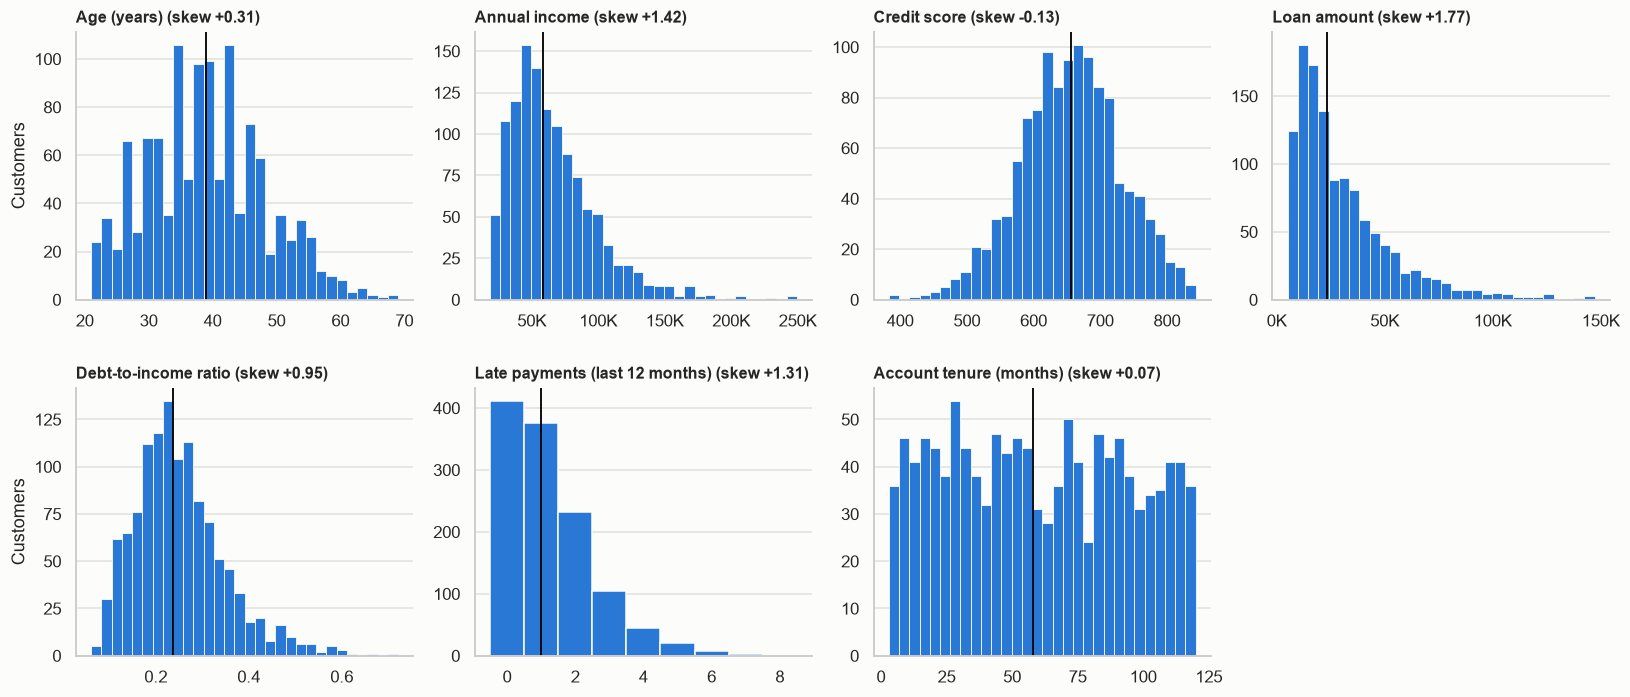

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, col in zip(axes.flat, NUMERIC_COLS):
    is_count = col == "late_payments_12m"
    sns.histplot(x=df[col], bins="auto" if is_count else 30, discrete=is_count,
                 color=BLUE, alpha=1, edgecolor=SURFACE, ax=ax)
    ax.axvline(df[col].median(), color="black", linewidth=1.2)  # median
    if col in ("annual_income", "loan_amount"):
        ax.xaxis.set_major_formatter(thousands)
    ax.set_title(f"{LABELS[col]} (skew {df[col].skew():+.2f})", fontsize=10.5)
    ax.set_xlabel("")
    ax.set_ylabel("Customers" if ax in axes[:, 0] else "")
    ax.grid(axis="x", visible=False)

axes.flat[-1].axis("off")
fig.tight_layout(h_pad=2)
fig.savefig(RESULTS_DIR / "eda_02_numeric_distributions.png")
plt.show()

**Findings** (black line = median)
- Credit score and age are roughly symmetric; account tenure is spread evenly from 3 to 120 months.
- **Annual income and loan amount are strongly right-skewed** (skew +1.42 and +1.77). A log transform is recommended for Logistic Regression, k-NN and MLP; tree-based models are not affected.
- Late payments is a count: about two thirds of customers have zero or one.

## 5. Features vs. loan default

Each numeric feature is compared between defaulters and non-defaulters using the Spearman
correlation and a Mann-Whitney U test (which does not assume normality). Employment status is
tested with a chi-square test.

In [6]:
y = df[TARGET]
rows = []
for col in NUMERIC_COLS:
    repaid, defaulted = df.loc[y == 0, col], df.loc[y == 1, col]
    rows.append({
        "feature": col,
        "median_repaid": repaid.median(),
        "median_defaulted": defaulted.median(),
        "spearman_r": stats.spearmanr(df[col], y).statistic,
        "p_value": stats.mannwhitneyu(repaid, defaulted).pvalue,
    })
association = pd.DataFrame(rows).set_index("feature")
association["significant"] = association["p_value"] < 0.05
association = association.sort_values("spearman_r", key=abs, ascending=False)
association.to_csv(RESULTS_DIR / "eda_feature_target_association.csv")

chi_p = stats.chi2_contingency(pd.crosstab(df["employment_status"], y)).pvalue
print(f"employment_status vs loan_default: chi-square p-value = {chi_p:.3f}")
association.round(4)

employment_status vs loan_default: chi-square p-value = 0.543


,median_repaid,median_defaulted,spearman_r,p_value,significant
feature,,,,,
credit_score,669.000,594.500,-0.3995,0.0000,True
late_payments_12m,1.000,2.000,0.3630,0.0000,True
debt_to_income_ratio,0.228,0.271,0.1680,0.0000,True
annual_income,59904.440,52793.590,-0.1037,0.0003,True
account_tenure_months,61.000,50.000,-0.0646,0.0252,True
age,39.000,38.000,-0.0465,0.1071,False
loan_amount,22661.605,24460.025,0.0384,0.1838,False


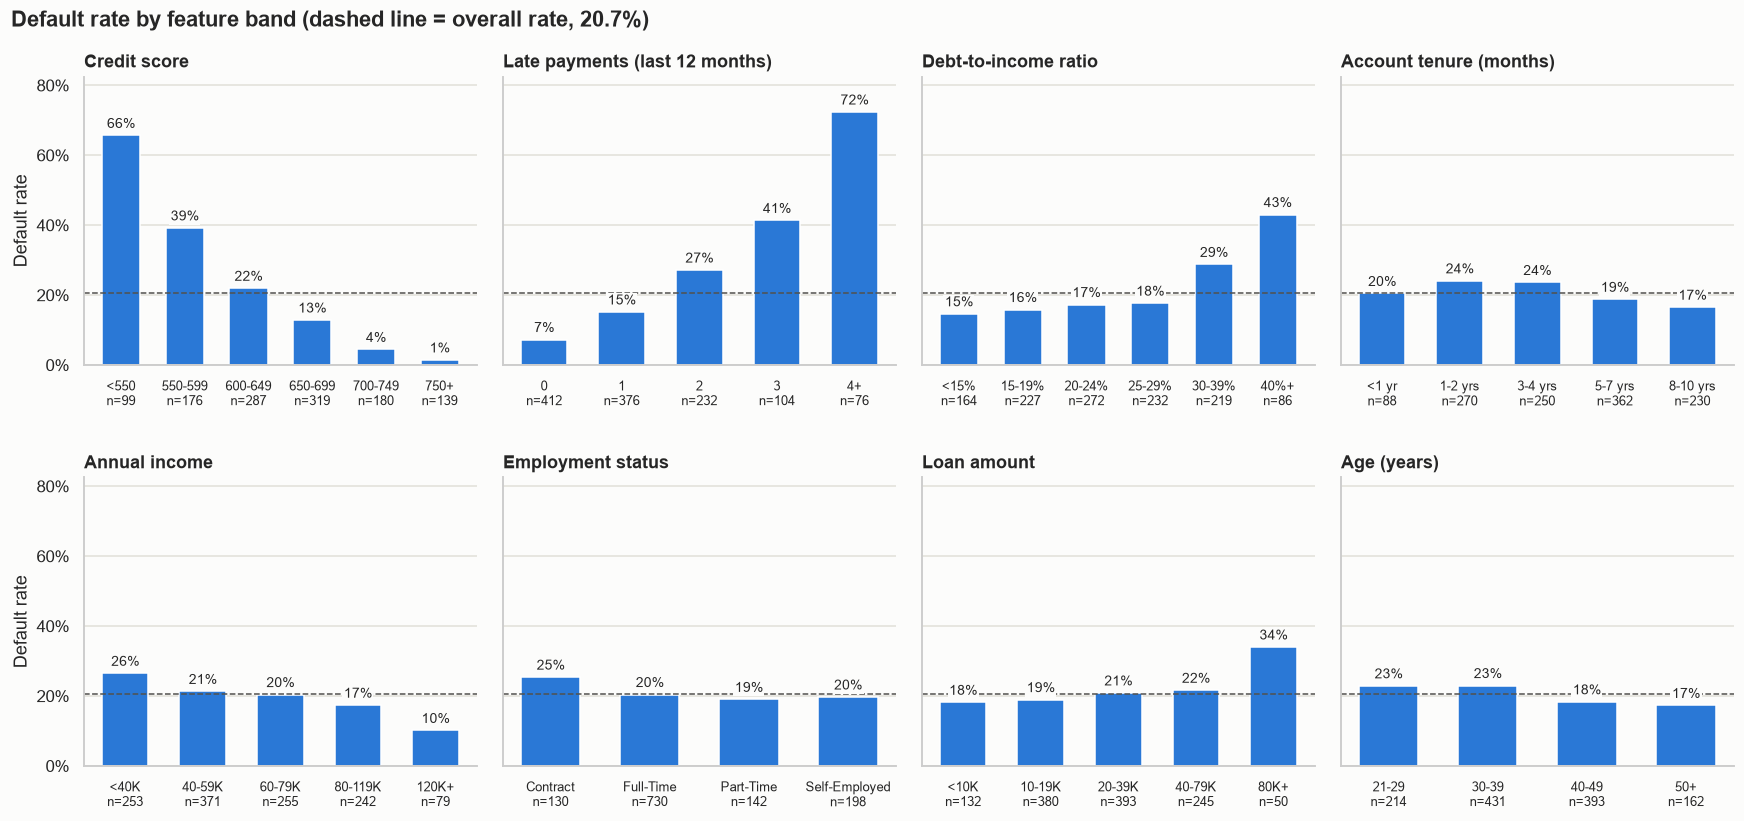

In [7]:
def band(col, edges, labels):
    return pd.cut(df[col], bins=edges, labels=labels, right=False)


bands = {
    "credit_score": band("credit_score", [300, 550, 600, 650, 700, 750, 851],
                         ["<550", "550-599", "600-649", "650-699", "700-749", "750+"]),
    "late_payments_12m": band("late_payments_12m", [0, 1, 2, 3, 4, 9], ["0", "1", "2", "3", "4+"]),
    "debt_to_income_ratio": band("debt_to_income_ratio", [0, 0.15, 0.20, 0.25, 0.30, 0.40, 1.0],
                                 ["<15%", "15-19%", "20-24%", "25-29%", "30-39%", "40%+"]),
    "account_tenure_months": band("account_tenure_months", [0, 12, 36, 60, 96, 121],
                                  ["<1 yr", "1-2 yrs", "3-4 yrs", "5-7 yrs", "8-10 yrs"]),
    "annual_income": band("annual_income", [0, 40e3, 60e3, 80e3, 120e3, 1e9],
                          ["<40K", "40-59K", "60-79K", "80-119K", "120K+"]),
    "employment_status": df["employment_status"],
    "loan_amount": band("loan_amount", [0, 10e3, 20e3, 40e3, 80e3, 1e9],
                        ["<10K", "10-19K", "20-39K", "40-79K", "80K+"]),
    "age": band("age", [21, 30, 40, 50, 71], ["21-29", "30-39", "40-49", "50+"]),
}

fig, axes = plt.subplots(2, 4, figsize=(16, 7.6), sharey=True)
for ax, (col, groups) in zip(axes.flat, bands.items()):
    table = df.groupby(groups, observed=True)[TARGET].agg(["mean", "size"])
    tick_labels = [f"{label}\nn={n}" for label, n in zip(table.index, table["size"])]
    bars = ax.bar(tick_labels, table["mean"], color=BLUE, width=0.6)
    ax.bar_label(bars, labels=[f"{rate:.0%}" for rate in table["mean"]], padding=3, fontsize=9,
                 bbox={"facecolor": SURFACE, "edgecolor": "none", "pad": 1})
    ax.axhline(overall_rate, color=GREY, linewidth=1, linestyle="--", zorder=1)
    ax.set_title(LABELS[col])
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.tick_params(axis="x", labelsize=8.5)
    ax.grid(axis="x", visible=False)
    ax.margins(y=0.14)

axes[0, 0].set_ylabel("Default rate")
axes[1, 0].set_ylabel("Default rate")
fig.suptitle(f"Default rate by feature band (dashed line = overall rate, {overall_rate:.1%})",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(h_pad=2.5)
fig.savefig(RESULTS_DIR / "eda_03_default_rate_by_feature.png")
plt.show()

**Findings**
- **Credit score is the strongest predictor** (Spearman −0.40). The default rate falls from 66% for scores below 550 to 1% for 750 and above.
- **Late payments is second** (Spearman +0.36). The default rate rises from 7% with no late payments to 72% with four or more.
- **Debt-to-income ratio acts like a threshold**: the default rate stays at 15–18% below a ratio of 30%, then jumps to 43% above 40%.
- Annual income and account tenure are weak but significant: lower earners and newer customers default slightly more.
- **Age, loan amount and employment status are not significant on their own** (p = 0.11, 0.18 and 0.54).

## 6. Correlation between features

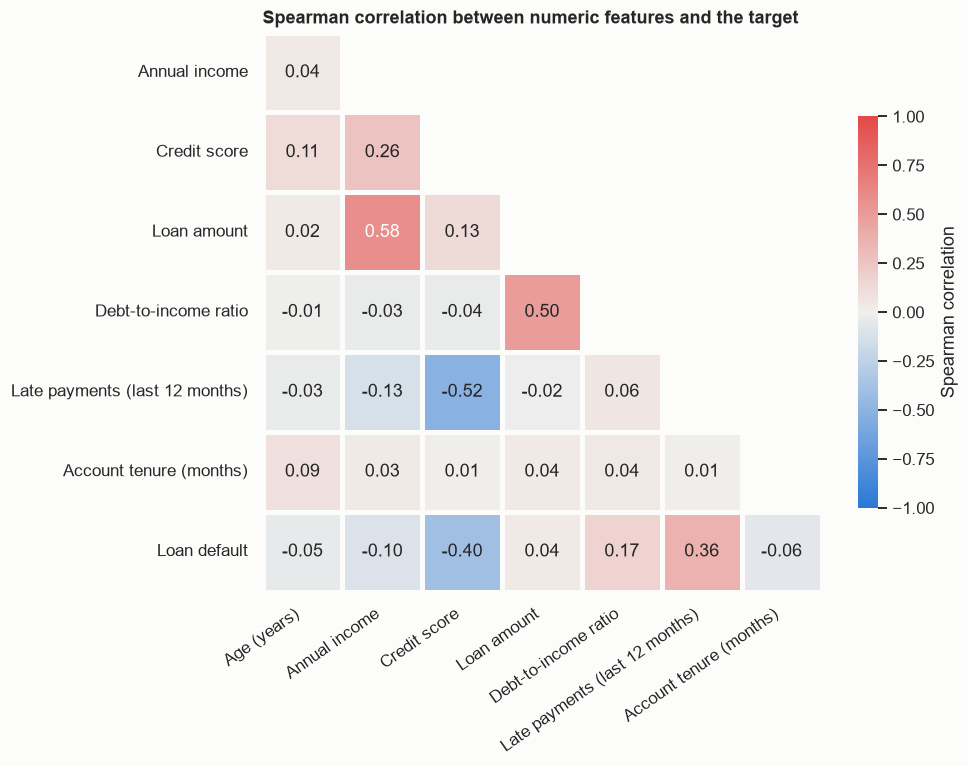

In [8]:
corr = df[NUMERIC_COLS + [TARGET]].corr(method="spearman")
lower = corr.iloc[1:, :-1]  # lower triangle only: the matrix is symmetric
hide = np.triu(np.ones_like(lower, dtype=bool), k=1)
blue_grey_red = LinearSegmentedColormap.from_list("blue_grey_red", [BLUE, "#f0efec", RED])

fig, ax = plt.subplots(figsize=(8.6, 6.6))
sns.heatmap(lower, mask=hide, cmap=blue_grey_red, vmin=-1, vmax=1, annot=True, fmt=".2f",
            linewidths=2, linecolor=SURFACE, square=True,
            cbar_kws={"shrink": 0.7, "label": "Spearman correlation"}, ax=ax)
ax.set_xticklabels([LABELS[c] for c in lower.columns], rotation=35, ha="right")
ax.set_yticklabels([LABELS[c] for c in lower.index], rotation=0)
ax.set_title("Spearman correlation between numeric features and the target")
ax.grid(False)
fig.savefig(RESULTS_DIR / "eda_04_correlation_heatmap.png")
plt.show()

**Findings**
- The strongest correlations between features are income with loan amount (+0.58), credit score with late payments (−0.52), and loan amount with debt-to-income ratio (+0.50).
- None is close to ±0.8, so **no feature needs to be removed** for multicollinearity.
- Loan amount is almost unrelated to default (+0.04) because it mainly follows income. A **loan-to-income ratio** is likely to be a more useful feature.

## 7. Customer remarks

A quick check of whether the wording of `customer_remark` is related to default. Remarks are
grouped by tone using two short keyword lists.

In [9]:
remarks = df["customer_remark"]
words = remarks.str.split().str.len()
print(f"Unique remarks: {remarks.nunique():,} of {len(df):,}")
print(f"Words per remark: {words.min()}-{words.max()} (median {words.median():.0f})")

STRAIN = "tight|strain|stretch|pressur|stress|struggl|worr|anxious|overwhelm|difficult|shortfall"
POSITIVE = "strong|solid|stable|steady|healthy|sound|disciplin|resilient|robust|balanced|comfortabl"
has_strain = remarks.str.contains(STRAIN, case=False)
has_positive = remarks.str.contains(POSITIVE, case=False)
tone = np.select(
    [has_strain & ~has_positive, has_positive & ~has_strain, has_strain & has_positive],
    ["Strain wording", "Positive wording", "Both"], default="Neutral")

tone_table = df.groupby(tone)[TARGET].agg(customers="size", default_rate="mean")
tone_table.sort_values("default_rate", ascending=False).style.format({"default_rate": "{:.1%}"})

Unique remarks: 1,188 of 1,200
Words per remark: 13-30 (median 20)


,customers,default_rate
Strain wording,247,36.8%
Both,15,20.0%
Neutral,571,19.1%
Positive wording,367,12.3%


**Findings**
- Remarks are short (13–30 words) and almost all unique, so they need text processing, not category encoding.
- **Wording is related to default**: remarks with strain wording default at 36.8%, against 12.3% for positive wording and 19.1% for neutral remarks.
- Keyword matching is only a rough check. Extracting sentiment and risk properly is left to the LLM/SLM in notebook `03`.

## 8. Summary

**Key findings**
1. The data is clean: 1,200 rows, no missing values, no duplicates.
2. The target is imbalanced: 20.7% default against 79.3% repaid.
3. Credit score and late payments are the strongest predictors of default; debt-to-income ratio matters mainly above 30%.
4. Age, loan amount and employment status are not significant on their own.
5. Income and loan amount are right-skewed; no pair of features is correlated strongly enough to drop.
6. The wording of customer remarks carries signal about default.

**Recommendations for the next notebooks**
- Drop `customer_id` and one-hot encode `employment_status`.
- Add a loan-to-income ratio and log-transform income and loan amount for scale-sensitive models.
- Use the LLM/SLM to extract sentiment and risk from `customer_remark`.
- Use a stratified train/test split and compare models on F1-score and ROC-AUC, not accuracy alone.